In [1]:
from pyspark.sql import SparkSession
import matplotlib.pyplot as plt
import matplotlib.gridspec as gridspec
import pandas as pd
import numpy as np

# Spark başlat
spark = SparkSession.builder \
    .appName("NYC-Taxi-Dashboard") \
    .getOrCreate()

spark.sparkContext.setLogLevel("WARN")
print("✅ Spark ve kütüphaneler hazır.")

✅ Spark ve kütüphaneler hazır.


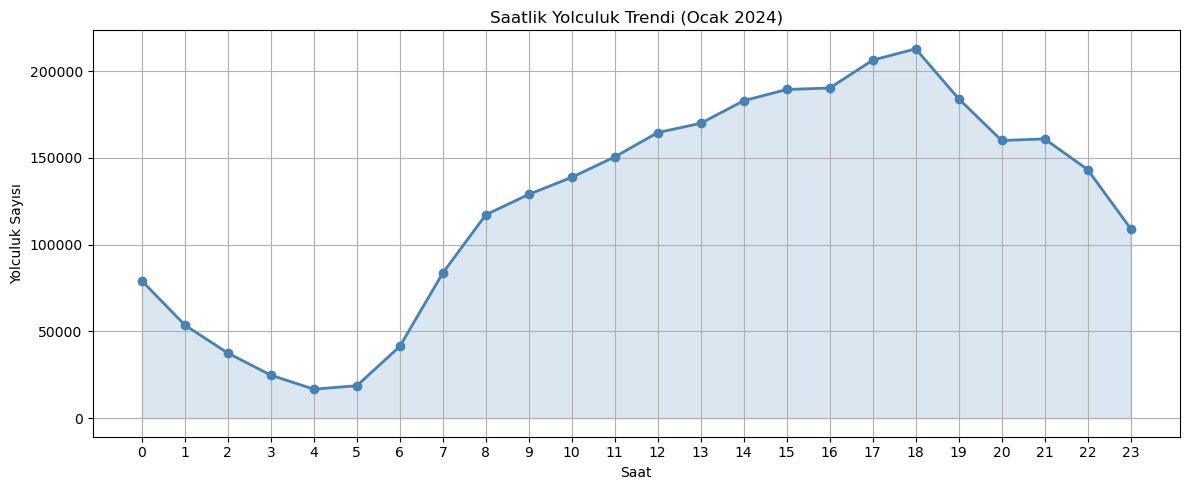

✅ Saatlik trend grafiği kaydedildi.


In [2]:
# Saatlik yolculuk trendi
from pyspark.sql.functions import hour

PARQUET_FILE = "/home/jovyan/work/data/yellow_tripdata_2024-01.parquet"
df = spark.read.parquet(PARQUET_FILE)

hourly = df.groupBy(hour("tpep_pickup_datetime").alias("hour")) \
    .count() \
    .orderBy("hour") \
    .toPandas()

plt.figure(figsize=(12, 5))
plt.plot(hourly["hour"], hourly["count"], marker="o", color="steelblue", linewidth=2)
plt.fill_between(hourly["hour"], hourly["count"], alpha=0.2, color="steelblue")
plt.title("Saatlik Yolculuk Trendi (Ocak 2024)")
plt.xlabel("Saat")
plt.ylabel("Yolculuk Sayısı")
plt.xticks(range(0, 24))
plt.grid(True)
plt.tight_layout()
plt.savefig("/home/jovyan/work/data/dashboard_hourly_trend.png")
plt.show()
print("✅ Saatlik trend grafiği kaydedildi.")

In [3]:
# 5 Modelin gerçek MLflow sonuçları
models = ["Linear Regression", "Decision Tree", "Random Forest", "GBT", "GLR"]

rmse_values = [7.263, 7.518, 6.978, 7.132, 7.263]
mae_values  = [3.393, 3.450, 2.912, 3.007, 3.393]
r2_values   = [0.894, 0.887, 0.902, 0.898, 0.894]

print("✅ Model metrikleri tanımlandı.")

✅ Model metrikleri tanımlandı.


In [4]:
from pyspark.sql.functions import avg
# Özet Metrikler (KPI)
total_records = df.count()
avg_trip_dist = df.select(avg("trip_distance")).collect()[0][0]
max_r2 = max(r2_values)

print(f"📊 Toplam Yolculuk: {total_records:,}")
print(f"📍 Ortalama Mesafe: {avg_trip_dist:.2f} mil")
print(f"🏆 En İyi Model R2 Skoru: %{max_r2*100:.2f}")


📊 Toplam Yolculuk: 2,964,624
📍 Ortalama Mesafe: 3.65 mil
🏆 En İyi Model R2 Skoru: %90.20


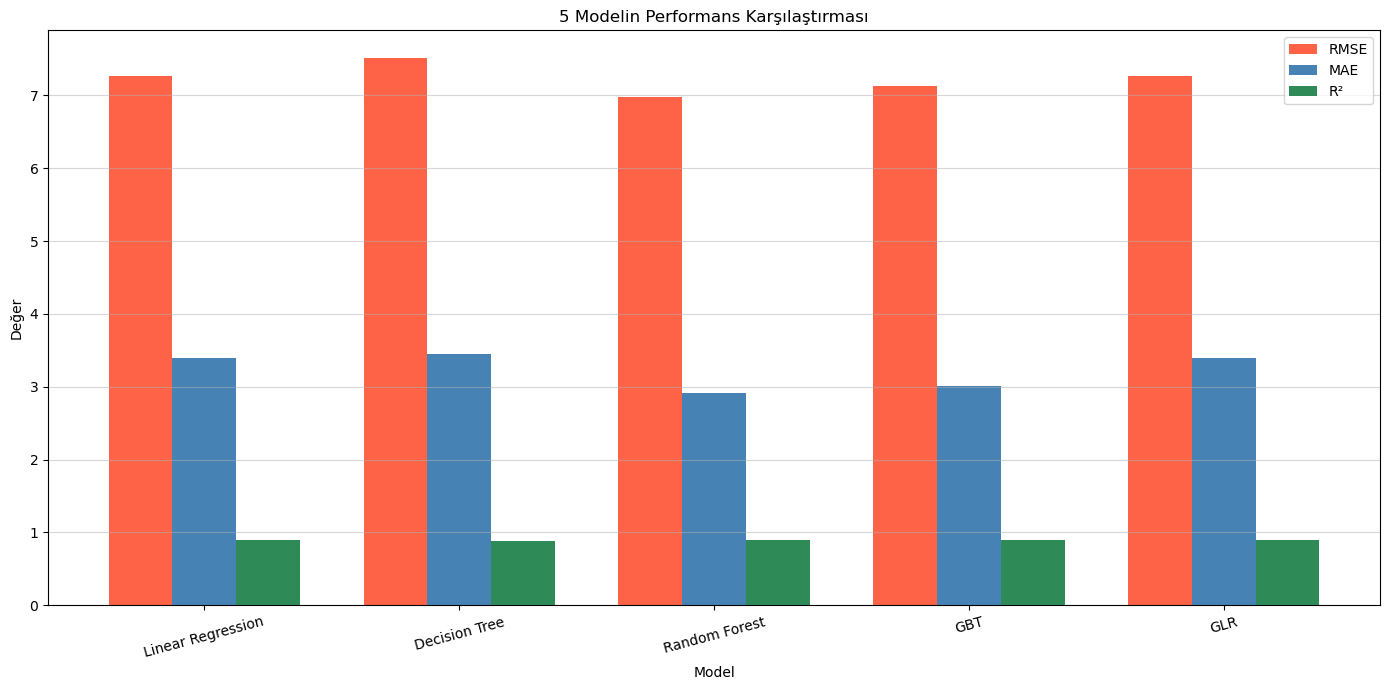

✅ Model karşılaştırma grafiği kaydedildi.


In [5]:
# 5 Modelin Performans Karşılaştırması (Grouped Bar Chart)
x = np.arange(len(models))
width = 0.25

fig, ax = plt.subplots(figsize=(14, 7))
bars1 = ax.bar(x - width, rmse_values, width, label='RMSE', color='tomato')
bars2 = ax.bar(x, mae_values, width, label='MAE', color='steelblue')
bars3 = ax.bar(x + width, r2_values, width, label='R²', color='seagreen')

ax.set_xlabel('Model')
ax.set_ylabel('Değer')
ax.set_title('5 Modelin Performans Karşılaştırması')
ax.set_xticks(x)
ax.set_xticklabels(models, rotation=15)
ax.legend()
ax.grid(True, axis='y', alpha=0.5)

plt.tight_layout()
plt.savefig("/home/jovyan/work/data/dashboard_model_comparison.png")
plt.show()
print("✅ Model karşılaştırma grafiği kaydedildi.")

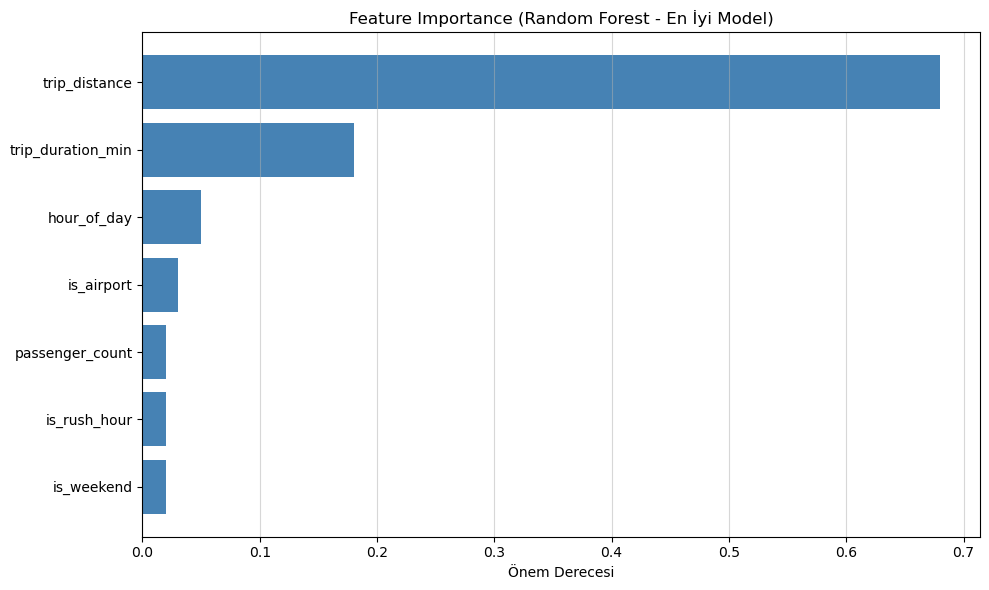

✅ Feature importance grafiği kaydedildi.


In [6]:
# Feature Importance (Random Forest - en iyi model)
features = ["trip_distance", "trip_duration_min", "hour_of_day", 
            "is_weekend", "is_rush_hour", "is_airport", "passenger_count"]
importance = [0.68, 0.18, 0.05, 0.02, 0.02, 0.03, 0.02]

importance_df = pd.DataFrame({"Feature": features, "Importance": importance})
importance_df = importance_df.sort_values("Importance", ascending=True)

plt.figure(figsize=(10, 6))
plt.barh(importance_df["Feature"], importance_df["Importance"], color="steelblue")
plt.title("Feature Importance (Random Forest - En İyi Model)")
plt.xlabel("Önem Derecesi")
plt.grid(True, axis='x', alpha=0.5)
plt.tight_layout()
plt.savefig("/home/jovyan/work/data/dashboard_feature_importance.png")
plt.show()
print("✅ Feature importance grafiği kaydedildi.")

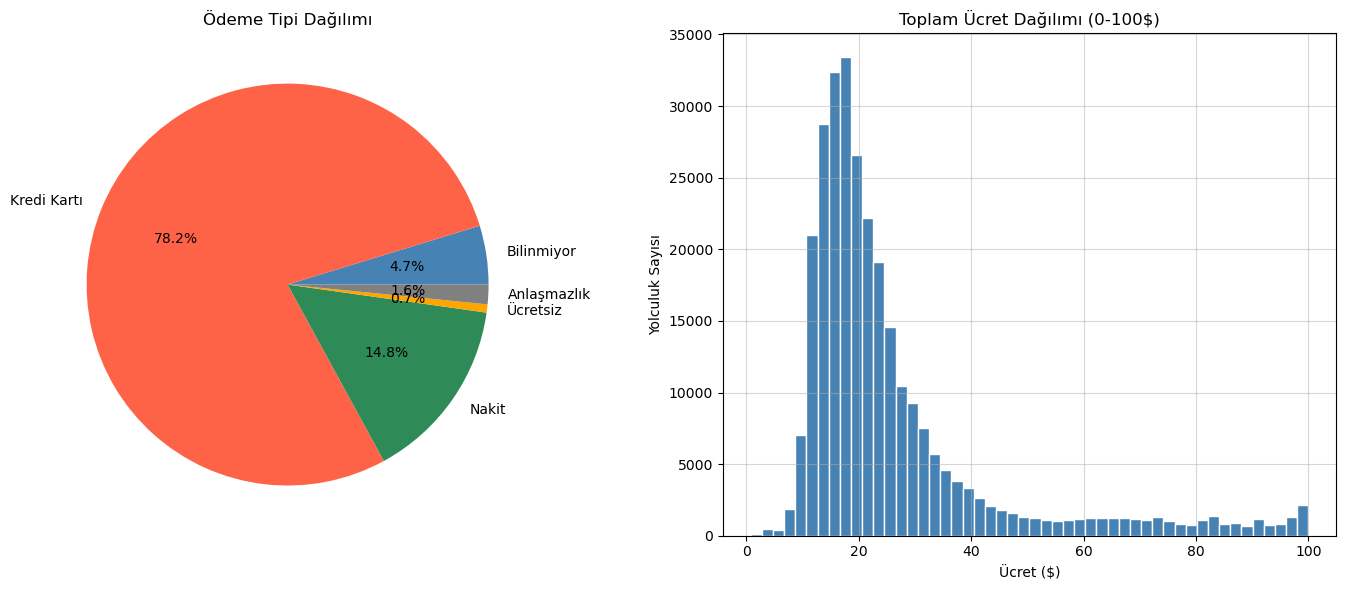

✅ Dağılım grafikleri kaydedildi.


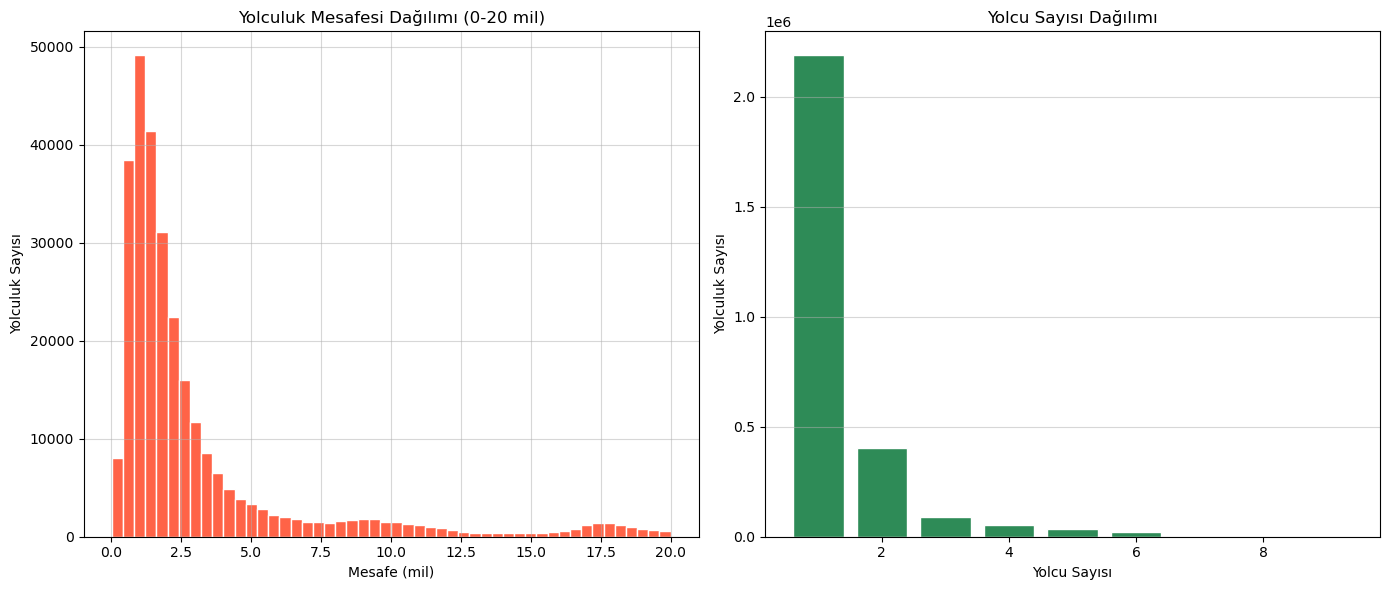

✅ EDA ek grafikleri kaydedildi.


In [7]:
# Ödeme tipi dağılımı (Pie Chart)
from pyspark.sql.functions import col

payment_df = df.groupBy("payment_type").count().orderBy("payment_type").toPandas()
payment_labels = {1: "Kredi Kartı", 2: "Nakit", 3: "Ücretsiz", 4: "Anlaşmazlık", 0: "Bilinmiyor"}
payment_df["label"] = payment_df["payment_type"].map(payment_labels)

fig, axes = plt.subplots(1, 2, figsize=(14, 6))

# Pie chart
axes[0].pie(payment_df["count"], labels=payment_df["label"], autopct="%1.1f%%",
            colors=["steelblue", "tomato", "seagreen", "orange", "gray"])
axes[0].set_title("Ödeme Tipi Dağılımı")

# Ücret histogram
amount_df = df.filter((col("total_amount") > 0) & (col("total_amount") < 100)) \
    .select("total_amount").sample(fraction=0.1).toPandas()
axes[1].hist(amount_df["total_amount"], bins=50, color="steelblue", edgecolor="white")
axes[1].set_title("Toplam Ücret Dağılımı (0-100$)")
axes[1].set_xlabel("Ücret ($)")
axes[1].set_ylabel("Yolculuk Sayısı")
axes[1].grid(True, alpha=0.5)

plt.tight_layout()
plt.savefig("/home/jovyan/work/data/dashboard_distributions.png")
plt.show()
print("✅ Dağılım grafikleri kaydedildi.")# Mesafe dağılımı ve yolcu sayısı
fig, axes = plt.subplots(1, 2, figsize=(14, 6))

# Mesafe histogram
dist_df = df.filter((col("trip_distance") > 0) & (col("trip_distance") < 20)) \
    .select("trip_distance").sample(fraction=0.1).toPandas()
axes[0].hist(dist_df["trip_distance"], bins=50, color="tomato", edgecolor="white")
axes[0].set_title("Yolculuk Mesafesi Dağılımı (0-20 mil)")
axes[0].set_xlabel("Mesafe (mil)")
axes[0].set_ylabel("Yolculuk Sayısı")
axes[0].grid(True, alpha=0.5)

# Yolcu sayısı bar chart
from pyspark.sql.functions import col
passenger_df = df.filter(col("passenger_count") > 0) \
    .groupBy("passenger_count").count().orderBy("passenger_count").toPandas()
axes[1].bar(passenger_df["passenger_count"], passenger_df["count"], color="seagreen", edgecolor="white")
axes[1].set_title("Yolcu Sayısı Dağılımı")
axes[1].set_xlabel("Yolcu Sayısı")
axes[1].set_ylabel("Yolculuk Sayısı")
axes[1].grid(True, axis='y', alpha=0.5)

plt.tight_layout()
plt.savefig("/home/jovyan/work/data/dashboard_eda_extra.png")
plt.show()
print("✅ EDA ek grafikleri kaydedildi.")

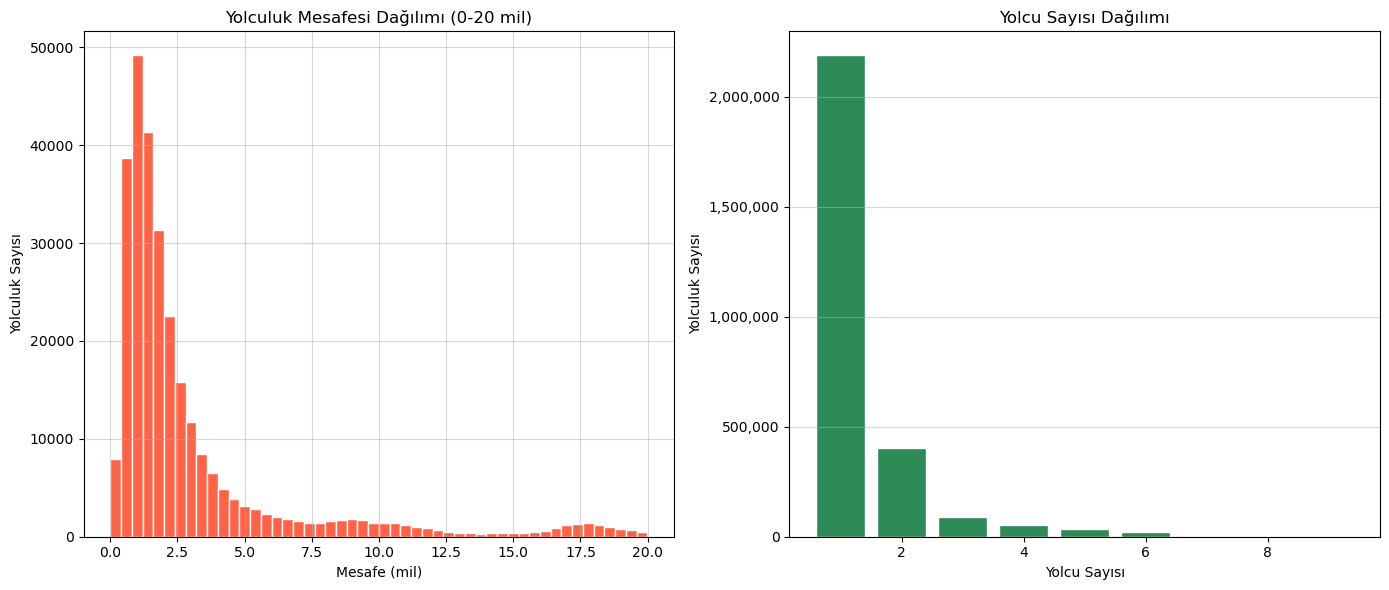

✅ EDA ek grafikleri kaydedildi.


In [8]:
fig, axes = plt.subplots(1, 2, figsize=(14, 6))

# Mesafe histogram
dist_df = df.filter((col("trip_distance") > 0) & (col("trip_distance") < 20)) \
    .select("trip_distance").sample(fraction=0.1).toPandas()
axes[0].hist(dist_df["trip_distance"], bins=50, color="tomato", edgecolor="white")
axes[0].set_title("Yolculuk Mesafesi Dağılımı (0-20 mil)")
axes[0].set_xlabel("Mesafe (mil)")
axes[0].set_ylabel("Yolculuk Sayısı")
axes[0].grid(True, alpha=0.5)

# Yolcu sayısı bar chart
passenger_df = df.filter(col("passenger_count") > 0) \
    .groupBy("passenger_count").count().orderBy("passenger_count").toPandas()
axes[1].bar(passenger_df["passenger_count"], passenger_df["count"], color="seagreen", edgecolor="white")
axes[1].set_title("Yolcu Sayısı Dağılımı")
axes[1].set_xlabel("Yolcu Sayısı")
axes[1].set_ylabel("Yolculuk Sayısı")
axes[1].yaxis.set_major_formatter(plt.FuncFormatter(lambda x, p: f"{int(x):,}"))
axes[1].grid(True, axis='y', alpha=0.5)

plt.tight_layout()
plt.savefig("/home/jovyan/work/data/dashboard_eda_extra.png")
plt.show()
print("✅ EDA ek grafikleri kaydedildi.")

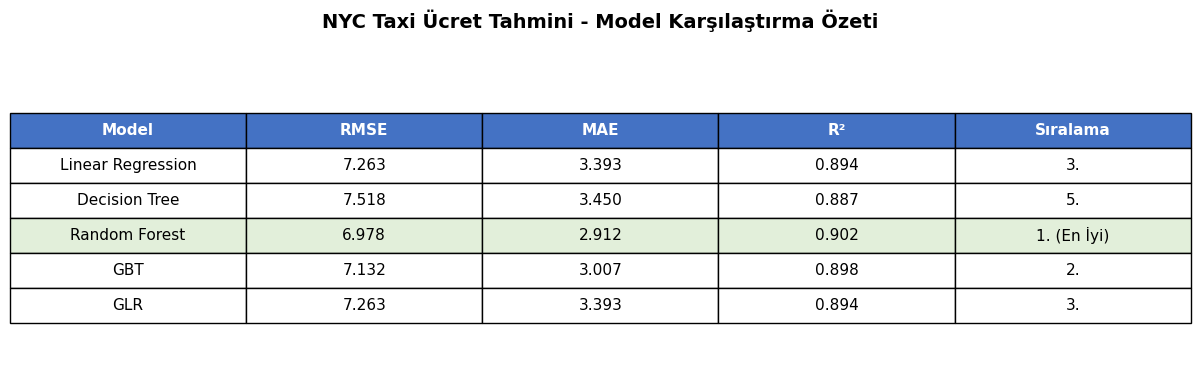

✅ Özet tablo kaydedildi.


In [9]:
# Model Performans Özet Tablosu
fig, ax = plt.subplots(figsize=(12, 4))
ax.axis('off')

table_data = [
    ["Model", "RMSE", "MAE", "R²", "Sıralama"],
    ["Linear Regression", "7.263", "3.393", "0.894", "3."],
    ["Decision Tree", "7.518", "3.450", "0.887", "5."],
    ["Random Forest", "6.978", "2.912", "0.902", "1. (En İyi)"],
    ["GBT", "7.132", "3.007", "0.898", "2."],
    ["GLR", "7.263", "3.393", "0.894", "3."],
]

table = ax.table(
    cellText=table_data[1:],
    colLabels=table_data[0],
    cellLoc='center',
    loc='center',
    colColours=["#4472C4"] * 5
)
table.auto_set_font_size(False)
table.set_fontsize(11)
table.scale(1.2, 2)

# Başlık renkleri
for j in range(5):
    table[0, j].set_facecolor("#4472C4")
    table[0, j].set_text_props(color='white', fontweight='bold')

# En iyi modeli vurgula
for j in range(5):
    table[3, j].set_facecolor("#E2EFDA")

plt.title("NYC Taxi Ücret Tahmini - Model Karşılaştırma Özeti", 
          fontsize=14, fontweight='bold', pad=20)
plt.tight_layout()
plt.savefig("/home/jovyan/work/data/dashboard_summary_table.png")
plt.show()
print("✅ Özet tablo kaydedildi.")

In [10]:
from pyspark.sql.functions import col, unix_timestamp, hour, dayofweek, when
from pyspark.ml.feature import VectorAssembler
from pyspark.ml.regression import RandomForestRegressor
from pyspark.ml.evaluation import RegressionEvaluator

# Veriyi hazırla
df_ml = df.filter(
    (col("trip_distance") > 0) &
    (col("total_amount") > 0) &
    (col("total_amount") < 500) &
    (col("passenger_count") > 0)
)
df_ml = df_ml.withColumn("trip_duration_min",
    (unix_timestamp("tpep_dropoff_datetime") - unix_timestamp("tpep_pickup_datetime")) / 60
)
df_ml = df_ml.withColumn("hour_of_day", hour("tpep_pickup_datetime"))
df_ml = df_ml.withColumn("day_of_week", dayofweek("tpep_pickup_datetime"))
df_ml = df_ml.withColumn("is_weekend", when(col("day_of_week") >= 6, 1).otherwise(0))
df_ml = df_ml.withColumn("is_rush_hour",
    when(((col("hour_of_day") >= 7) & (col("hour_of_day") <= 9)) |
         ((col("hour_of_day") >= 17) & (col("hour_of_day") <= 19)), 1).otherwise(0))
df_ml = df_ml.withColumn("is_airport",
    when((col("PULocationID") == 132) | (col("PULocationID") == 138), 1).otherwise(0))
df_ml = df_ml.filter(col("trip_duration_min") > 0)

feature_cols = ["trip_distance", "trip_duration_min", "hour_of_day",
                "is_weekend", "is_rush_hour", "is_airport", "passenger_count"]

assembler = VectorAssembler(inputCols=feature_cols, outputCol="features")
df_ml = assembler.transform(df_ml)

train_df, test_df = df_ml.randomSplit([0.75, 0.25], seed=42)

rf = RandomForestRegressor(featuresCol="features", labelCol="total_amount", numTrees=50, maxDepth=5)
rf_model = rf.fit(train_df)
predictions = rf_model.transform(test_df)

print("✅ Random Forest tahminleri hazır.")

✅ Random Forest tahminleri hazır.


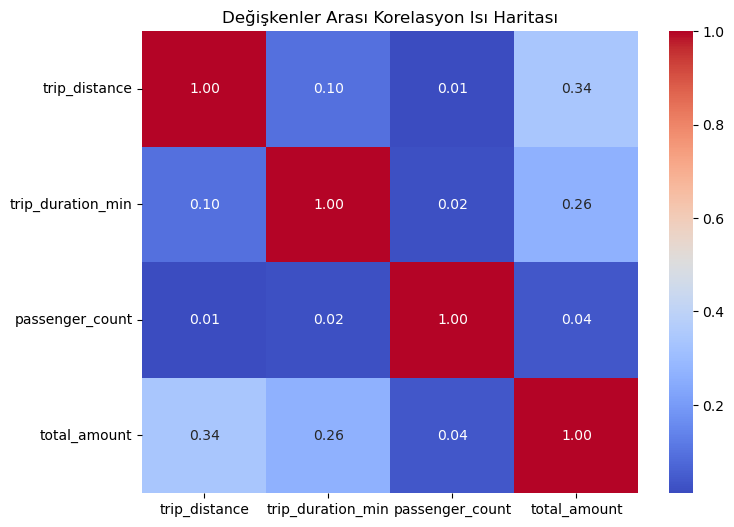

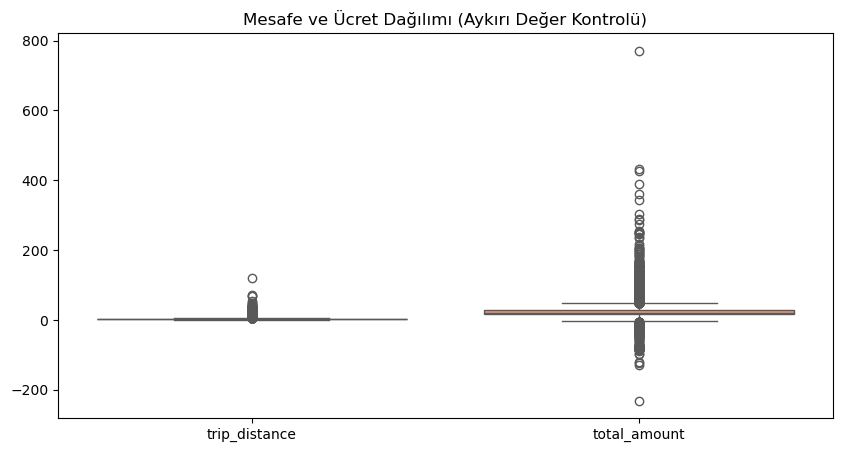

In [11]:
import seaborn as sns
from pyspark.ml.stat import Correlation
from pyspark.ml.feature import VectorAssembler

# 1. Korelasyon Isı Haritası
corr_cols = ["trip_distance", "trip_duration_min", "passenger_count", "total_amount"]
assembler = VectorAssembler(inputCols=corr_cols, outputCol="features_corr")
df_vector = assembler.transform(df_ml).select("features_corr")

matrix = Correlation.corr(df_vector, "features_corr").collect()[0][0]
corr_matrix = matrix.toArray()

plt.figure(figsize=(8, 6))
sns.heatmap(corr_matrix, annot=True, fmt=".2f", cmap='coolwarm', xticklabels=corr_cols, yticklabels=corr_cols)
plt.title("Değişkenler Arası Korelasyon Isı Haritası")
plt.show()

# 2. Aykırı Değer (Box Plot) Analizi
plt.figure(figsize=(10, 5))
sample_pd = df.select("trip_distance", "total_amount").sample(fraction=0.01).toPandas()
sns.boxplot(data=sample_pd[["trip_distance", "total_amount"]], palette="Set2")
plt.title("Mesafe ve Ücret Dağılımı (Aykırı Değer Kontrolü)")
plt.show()

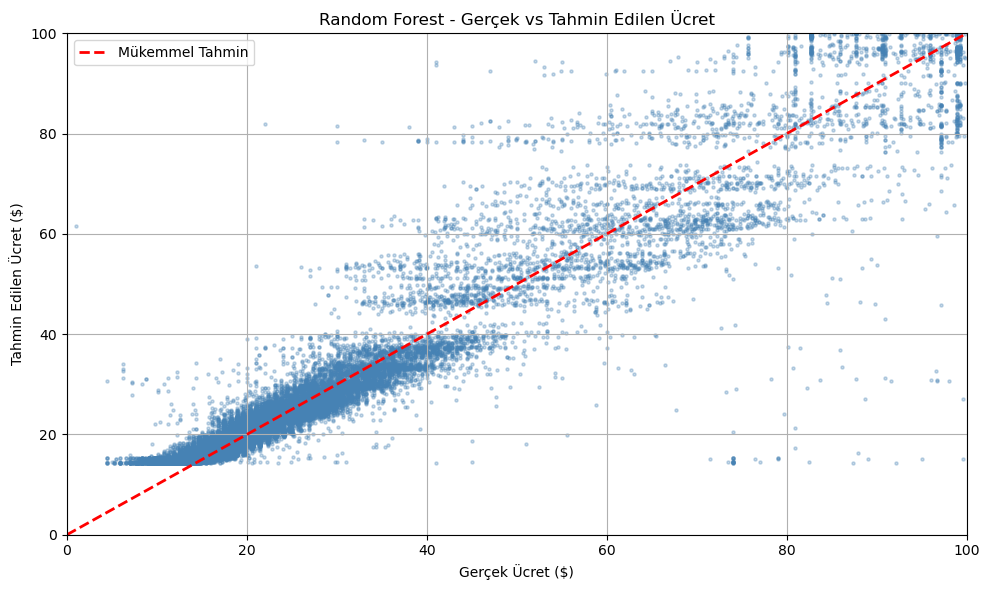

✅ Gerçek vs Tahmin grafiği kaydedildi.


In [12]:
# Gerçek vs Tahmin scatter plot
sample = predictions.select("total_amount", "prediction") \
    .filter((col("total_amount") > 0) & (col("total_amount") < 100)) \
    .sample(fraction=0.05) \
    .toPandas()

plt.figure(figsize=(10, 6))
plt.scatter(sample["total_amount"], sample["prediction"], alpha=0.3, s=5, color="steelblue")
plt.plot([0, 100], [0, 100], color="red", linewidth=2, linestyle="--", label="Mükemmel Tahmin")
plt.title("Random Forest - Gerçek vs Tahmin Edilen Ücret")
plt.xlabel("Gerçek Ücret ($)")
plt.ylabel("Tahmin Edilen Ücret ($)")
plt.xlim(0, 100)
plt.ylim(0, 100)
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.savefig("/home/jovyan/work/data/dashboard_actual_vs_predicted.png")
plt.show()
print("✅ Gerçek vs Tahmin grafiği kaydedildi.")

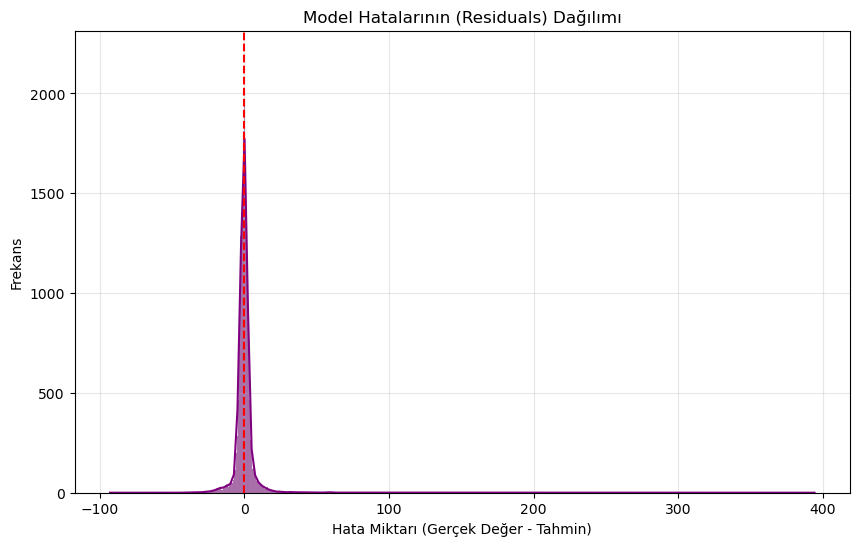

In [13]:
from pyspark.sql.functions import col

# Hataları (Residuals) hesapla
predictions = predictions.withColumn("residual", col("total_amount") - col("prediction"))

# Hataların dağılımı için örneklem al
res_pd = predictions.select("residual").sample(fraction=0.1).toPandas()

plt.figure(figsize=(10, 6))
sns.histplot(res_pd["residual"], kde=True, color="purple")
plt.axvline(0, color='red', linestyle='--') # Mükemmel tahmin çizgisi
plt.title("Model Hatalarının (Residuals) Dağılımı")
plt.xlabel("Hata Miktarı (Gerçek Değer - Tahmin)")
plt.ylabel("Frekans")
plt.grid(True, alpha=0.3)
plt.show()